# Training 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import time
import torch
import torch.nn as nn

from torchvision.models import ResNet50_Weights, resnet50
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image
from torchvision import transforms as T
from PIL import Image

CSV_PATH    = "sculpturesData.csv"
IMG_DIR     = "images"
LABEL_COL   = "Origin"
IMG_EXTS    = [".jpg", ".jpeg", ".png"]

SEED        = 5000
BATCH_SIZE  = 32
EPOCHS      = 8
LR          = 1e-4
NUM_WORKERS = 0
USE_CLASS_WEIGHTS = True # There are classes that has much less number of data

DEVICE = ("cuda" if torch.cuda.is_available()
          else "cpu")
print("device:", DEVICE)

allData = pd.read_csv(CSV_PATH, index_col=0)   # first column (the image file name) becomes the index
print(allData)

device: cpu
                                                  Title    Origin  \
0                                      Sitzender Buddha  Thailand   
1     Buddha in Bhumisparsa-Mudra beschirmt von Naga...  Thailand   
2                                      Liegender Buddha  Thailand   
3     Buddha in Bhumisparsa-Mudra und ein Jünger in ...   Myanmar   
4                                      Stehender Buddha   Myanmar   
...                                                 ...       ...   
1943                                     Head of Buddha     China   
1944                           Head of Emaciated Buddha  Gandhara   
1945               Relief of Śākyamuni Buddha Preaching  Gandhara   
1946                          Standing Śākyamuni Buddha  Gandhara   
1947                          Standing Śākyamuni Buddha  Gandhara   

               Source                                              Image  
0     Reitberg Museum  https://rietberg.ch/collection/Items/10686/_co...  
1     Rei

In [2]:
def find_image(name):
    name = str(name)
    if os.path.isfile(os.path.join(IMG_DIR, name)):          # index already includes the extension
        return os.path.join(IMG_DIR, name)
    for ext in IMG_EXTS:
        p = os.path.join(IMG_DIR, name + ext)
        if os.path.isfile(p):
            return p
    return None

allData["path"] = [find_image(i) for i in allData.index]
allData = allData.dropna(subset=["path", LABEL_COL])

CLASSES = sorted(allData[LABEL_COL].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
allData["label"] = allData[LABEL_COL].map(class_to_idx)
print("Number of Images:", len(allData))
print("Number of Classes:", len(CLASSES))
print(allData[LABEL_COL].value_counts().to_string())

Number of Images: 1948
Number of Classes: 10
Origin
China        801
Myanmar      304
Thailand     166
Japan        135
India        127
Gandhara     122
Tibet        107
Indonesia     87
Nepal         63
Cambodia      36


In [ ]:
# Divide to train, val, test
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []

# Divide each class to ensure we have data from every classes in three sets
for c in range(len(CLASSES)):
    rows = np.where(allData["label"].values == c)[0]
    rows = rng.permutation(rows)

    # use 70, 15, 15 instead because there are class with much less data
    # try to get more training data
    # 70-15-15 make it worse T^T
    n_tr = int(len(rows) * 0.6)
    n_va = int(len(rows) * 0.2)
    train_idx += rows[:n_tr].tolist()
    val_idx   += rows[n_tr:n_tr + n_va].tolist()
    test_idx  += rows[n_tr + n_va:].tolist()

trainSet = allData.iloc[rng.permutation(train_idx)]
valSet   = allData.iloc[rng.permutation(val_idx)]
testSet  = allData.iloc[rng.permutation(test_idx)]

trainSet.to_csv("./trainSet.csv")
valSet.to_csv("./valSet.csv")
testSet.to_csv("./testSet.csv")

print(f"train {len(trainSet)}   val {len(valSet)}   test {len(testSet)}")
print(pd.DataFrame({"train": trainSet[LABEL_COL].value_counts(),
                    "val":   valSet[LABEL_COL].value_counts(),
                    "test":  testSet[LABEL_COL].value_counts()}))

train 1165   val 386   test 397
           train  val  test
Origin                     
China        480  160   161
Myanmar      182   60    62
Thailand      99   33    34
Japan         81   27    27
India         76   25    26
Gandhara      73   24    25
Tibet         64   21    22
Indonesia     52   17    18
Nepal         37   12    14
Cambodia      21    7     8


In [4]:
weights = ResNet50_Weights.DEFAULT
tf_default = weights.transforms()

print(tf_default)
print()
print(f"  resize to      {tf_default.resize_size}")
print(f"  then crop to   {tf_default.crop_size}")
print(f"  mean           {tf_default.mean}")
print(f"  std            {tf_default.std}")

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

  resize to      [232]
  then crop to   [224]
  mean           [0.485, 0.456, 0.406]
  std            [0.229, 0.224, 0.225]


In [5]:
# Dataset
class SculptureDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

tf = T.Compose([
                    T.CenterCrop(224),
                    T.ToTensor(),
                    T.Normalize(mean = tf_default.mean, std = tf_default.std)
])

In [6]:
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(SculptureDataset(trainSet, tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, generator=g)
val_loader   = DataLoader(SculptureDataset(valSet, tf), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
test_loader  = DataLoader(SculptureDataset(testSet, tf), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)


In [7]:
def build(pretrained, freeze):
    torch.manual_seed(SEED)
    model = resnet50(weights=weights if pretrained else None)

    if freeze:
        for param in model.parameters():
            param.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))

    return model.to(DEVICE)

for pre, frz, name in [(True, False, "fine-tune")]:
    m = build(pre, frz)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"  {name:10s} {n:>12,} trainable of "
          f"{sum(p.numel() for p in m.parameters()):,}")

  fine-tune    23,528,522 trainable of 23,528,522


In [8]:
def eval(model, loader, lossf=None):
    model.eval()
    ys, ps, total_loss = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(DEVICE)).cpu()
            if lossf is not None:
                total_loss += lossf(out, y).item() * len(y)
            ys.append(y); ps.append(out.argmax(1))
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return 100 * (ys == ps).mean(), total_loss / len(ys), ys, ps

def train(model, epochs=EPOCHS, lr=LR):
    train_me = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(train_me, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    if USE_CLASS_WEIGHTS:
        counts = np.bincount(trainSet["label"].values, minlength=len(CLASSES))
        w = torch.tensor(len(trainSet) / (len(CLASSES) * counts), dtype=torch.float32)
        lossf = nn.CrossEntropyLoss(weight=w) 
        lossf_dev = nn.CrossEntropyLoss(weight=w.to(DEVICE))
    else:
        lossf = lossf_dev = nn.CrossEntropyLoss()

    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, t0 = -1, None, time.time()

    for ep in range(epochs):
        model.train()
        run_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = lossf_dev(model(x), y)
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(y)
        sched.step()

        val_acc, val_loss, _, _ = eval(model, val_loader, lossf)
        hist["train_loss"].append(run_loss / len(trainSet))
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f"  epoch {ep+1:2d}/{epochs}  train loss {hist['train_loss'][-1]:.3f}  "
              f"val loss {val_loss:.3f}  val acc {val_acc:5.2f}%  ({time.time()-t0:.0f}s)")

    model.load_state_dict(best_state)
    return hist, sum(p.numel() for p in train_me), time.time() - t0


runs = {}
for name, pre, frz, lr in [("fine-tuned", True, False, LR)]:
    model = build(pre, frz)
    hist, ntr, secs = train(model, lr=lr)
    runs[name] = (hist, ntr)
    print(f"\n  {name:11s} lr={lr:<6g} {ntr:>11,} trainable   "
          f"epoch 1 {hist['val_acc'][0]:5.2f}   best {max(hist['val_acc']):5.2f}   ({secs:.0f}s)")

  epoch  1/8  train loss 2.144  val loss 1.838  val acc 54.15%  (247s)
  epoch  2/8  train loss 1.347  val loss 1.444  val acc 59.59%  (523s)
  epoch  3/8  train loss 0.722  val loss 1.258  val acc 69.17%  (812s)
  epoch  4/8  train loss 0.333  val loss 1.242  val acc 69.95%  (1096s)
  epoch  5/8  train loss 0.166  val loss 1.263  val acc 72.02%  (1391s)
  epoch  6/8  train loss 0.109  val loss 1.273  val acc 73.32%  (1681s)
  epoch  7/8  train loss 0.086  val loss 1.316  val acc 72.80%  (1976s)
  epoch  8/8  train loss 0.074  val loss 1.281  val acc 74.09%  (2301s)

  fine-tuned  lr=0.0001  23,528,522 trainable   epoch 1 54.15   best 74.09   (2301s)


In [19]:
test_acc, _, y_true, y_pred = eval(model, test_loader)
print(f"TEST accuracy: {test_acc:.2f}%  ({(y_true == y_pred).sum()}/{len(y_true)})\n")

# confusion matrix (rows = true class, columns = predicted class)
K = len(CLASSES)
cm = np.zeros((K, K), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

# per-class precision / recall
print(f"{'class':12s} {'precision':>9s}")
for i, c in enumerate(CLASSES):
    prec = cm[i, i] / max(cm[:, i].sum(), 1)
    print(f"{c:12s} {prec:9.2f}")

TEST accuracy: 70.78%  (281/397)

class        precision
Cambodia          0.17
China             0.81
Gandhara          0.63
India             0.50
Indonesia         0.54
Japan             0.67
Myanmar           0.91
Nepal             0.00
Thailand          0.61
Tibet             0.45


# Single Image Test
## Using Random image outside of any set

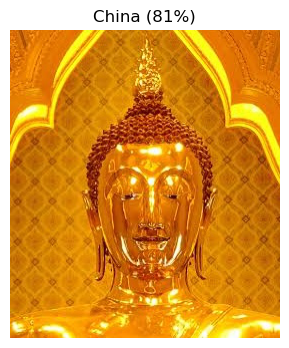

  China        0.807
  Nepal        0.051
  Japan        0.037


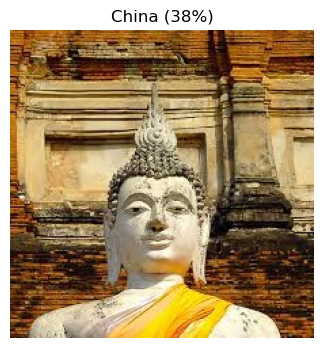

  China        0.379
  Gandhara     0.265
  India        0.237


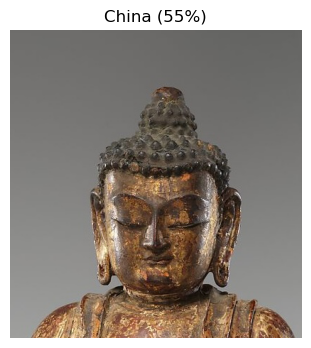

  China        0.548
  Thailand     0.261
  Nepal        0.060


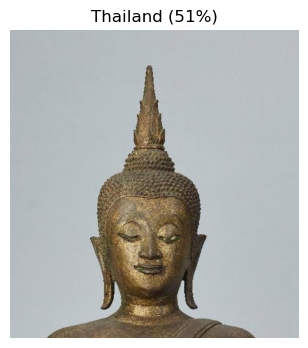

  Thailand     0.509
  China        0.156
  Gandhara     0.122


In [18]:
def predict(path, topk=3):
    model.eval()
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        probs = torch.softmax(model(tf(img).unsqueeze(0).to(DEVICE)), dim=1)[0].cpu()
    p, i = probs.topk(min(topk, len(CLASSES)))
    plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
    plt.title(f"{CLASSES[i[0]]} ({p[0]:.0%})"); plt.show()
    for pi, ii in zip(p, i):
        print(f"  {CLASSES[ii]:12s} {pi:.3f}")


predict("sukhothai.jpeg")
predict("sukhothai2.jpeg")
predict("ChineseSculpture.jpeg")
predict("Ayutthaya.jpg")